# **Previsão do Consumo Energético de Edifícios para Apoio à Gestão Inteligente - Componente Elétrica**

Edifícios: **ABR, C e ICSTM**, anos **2019 e 2020**. \
Dataset: *University campus buildings electrical and thermal demand and generation* (Zenodo, projeto E-LAND).


## Configuração e carregamento dos dados

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

EDIFICIOS = ["ABR", "C", "ICSTM"]
TIPO = "elec"
CORES = {2019: "#8AC926", 2020: "#6A4C93"}

def nome_ficheiro(tipo, edificio):
    if tipo == "heat" and edificio == "ICSTM":
        return "UVTgv_heat_demand_building_ICSTM_2019.csv"
    return f"UVTgv_{tipo}_{edificio}_2019_2020.csv"

# sobe até à raiz do repositório (a pasta que contém "dataset")
RAIZ = Path.cwd()
while not (RAIZ / "dataset").exists():
    RAIZ = RAIZ.parent
PASTA_DADOS = RAIZ / "dataset" / "UVTgv_OD" / "demand"
DIAS = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]

partes = []
for ed in EDIFICIOS:
    df = pd.read_csv(PASTA_DADOS / nome_ficheiro(TIPO, ed), sep=";")
    for col in df.columns:
        ano = int(col[-4:])                        # também funciona com 'elec_ISCTM_2020'
        s = df[col].astype(float)
        horas = pd.date_range(f"{ano}-01-01 00:00", f"{ano}-12-31 23:00", freq="h")
        horas = horas[~((horas.month == 2) & (horas.day == 29))]    # assume-se que o dia 29 de fevereiro não existe
        s.index = horas                                             # 8760 horas em cada ano
        partes.append(pd.DataFrame({"consumo": s, "edificio": ed, "ano": ano}))

d = pd.concat(partes).sort_index(kind="stable")
d["hora"] = d.index.hour
d["dia_semana"] = d.index.dayofweek          # 0 = segunda
d["mes"] = d.index.month
d["fim_semana"] = d["dia_semana"] >= 5
# 2020 é tratado como um ano de 365 dias (sem 29 de fevereiro): dia do ano e hora do ano comparáveis com 2019
d["dia_ano"] = d.index.dayofyear - ((d.index.year == 2020) & (d.index >= "2020-03-01")).astype(int)
d["hora_ano"] = (d["dia_ano"] - 1) * 24 + d["hora"]
anos = [2019, 2020]
d.head()

,consumo,edificio,ano,hora,dia_semana,mes,fim_semana,dia_ano,hora_ano
2019-01-01 00:00:00,44.630080,ABR,2019,0,1,1,False,1,0
2019-01-01 00:00:00,15.042488,C,2019,0,1,1,False,1,0
2019-01-01 00:00:00,18.420000,ICSTM,2019,0,1,1,False,1,0
2019-01-01 01:00:00,45.302036,ABR,2019,1,1,1,False,1,1
2019-01-01 01:00:00,15.309816,C,2019,1,1,1,False,1,1


---
# 4.1. Análise exploratória dos dados

## Número de registos

In [84]:
print("Nº total de registos:", len(d))
print(d.groupby(["edificio", "ano"]).size().rename("registos").to_frame().T.to_string(), "\n")


Nº total de registos: 52560
edificio   ABR           C       ICSTM      
ano       2019  2020  2019  2020  2019  2020
registos  8760  8760  8760  8760  8760  8760 



Cada ficheiro anual tem 8760 registos horários. \
No total são 3 edifícios × 2 anos × 8760 = **52 560 registos**.

## Variável de consumo a prever e unidades

Variável a prever: **consumo horário de eletricidade de cada edifício**. \
Unidade: **kWh por hora**.

## Distribuição e variabilidade do consumo

In [85]:
resumo = d.groupby(["edificio", "ano"])["consumo"].describe()
resumo["CV"] = resumo["std"] / resumo["mean"]
resumo["skew"] = d.groupby(["edificio", "ano"])["consumo"].skew()
resumo.round(2)

count   mean    std   min    25%    50%    75%     max    CV  \
edificio ano                                                                   
ABR      2019  8760.0  42.37  26.31  7.11  22.84  36.40  51.78  193.21  0.62   
         2020  8760.0  30.25  14.02  8.73  20.09  27.23  36.63  126.76  0.46   
C        2019  8760.0  26.67  12.35  4.32  18.41  22.17  32.13   94.09  0.46   
         2020  8760.0  19.42  11.16  0.32  10.23  17.05  26.16   66.78  0.57   
ICSTM    2019  8760.0  24.19  16.77  0.00  16.15  20.29  26.82  204.70  0.69   
         2020  8760.0  17.61  24.62  0.00   8.16  14.37  17.78  235.94  1.40   

               skew  
edificio ano         
ABR      2019  1.40  
         2020  1.36  
C        2019  1.60  
         2020  0.96  
ICSTM    2019  3.82  
         2020  4.63

Com base na tabela, podemos ver que:
- O **consumo médio desceu de 2019 para 2020** em todos os edifícios.
- A **média é maior que a mediana**, o que revela uma assimetria com cauda à direita, ou seja, a **maior parte das horas tem consumo baixo ou moderado**, com alguns picos acima do normal.
- O **ICSTM tem o consumo menos estável dos três edifícios**, o que o torna o mais difícil de prever.

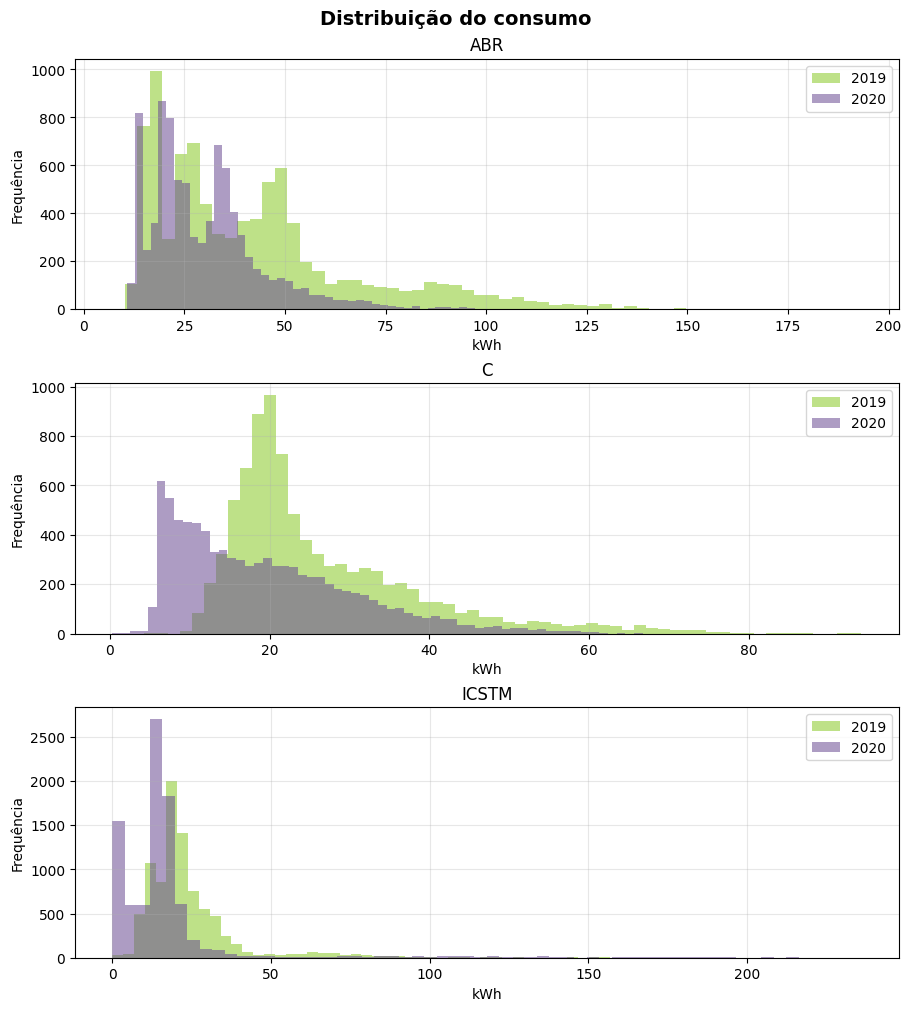

In [86]:
fig, axes = plt.subplots(3, 1, figsize=(9, 10), constrained_layout=True)
for ax, ed in zip(axes, EDIFICIOS):
    for a in anos:
        ax.hist(d[(d.edificio == ed) & (d.ano == a)]["consumo"], bins=60, alpha=0.55, color=CORES[a], label=str(a))
    ax.set_title(f"{ed}: distribuição do consumo")
    ax.set_xlabel("kWh"); ax.set_ylabel("Frequência")
    ax.legend(); ax.grid(alpha=0.3)
    ax.set_title(ed)
fig.suptitle("Distribuição do consumo", fontsize=14, fontweight="bold")
plt.show()

Com base nos histogramas, conseguimos verificar o que os valores da tabela anterior demonstravam - existe uma assimetria nos dados, com a maior parte das horas a ter consumo baixo ou moderado e algumas horas com consumo muito elevado (cauda à direita). \
Também, verifica-se o que foi dito acerca do edifício ICSTM, aquele que tem a cauda mais longa, que mostra ter o consumo mais irregular.

## Valores em falta ou inconsistentes

In [87]:
linhas = []
for (ed, a), g in d.groupby(["edificio", "ano"]):
    x = g["consumo"]
    q1, q3 = x.quantile([0.25, 0.75]); iqr = q3 - q1
    n_out = ((x > q3 + 1.5*iqr) | (x < q1 - 1.5*iqr)).sum()
    linhas.append({
        "edificio": ed, "ano": a,
        "em falta": int(x.isna().sum()),
        "<= 0": int((x <= 0).sum()),
        "duplicados": int(x.index.duplicated().sum()),
        "saltos ≠ 1h": int((g["hora_ano"].diff().dropna() != 1).sum()),
        "outliers IQR": int(n_out),
        "% outliers": round(100 * n_out / len(x), 1),
    })
pd.DataFrame(linhas).set_index(["edificio", "ano"])

em falta  <= 0  duplicados  saltos ≠ 1h  outliers IQR  \
edificio ano                                                           
ABR      2019         0     0           0            0           477   
         2020         0     0           0            0           326   
C        2019         0     0           0            0           460   
         2020         0     0           0            0           137   
ICSTM    2019         0    17           0            0           643   
         2020         0   652           0            0           546   

               % outliers  
edificio ano               
ABR      2019         5.4  
         2020         3.7  
C        2019         5.3  
         2020         1.6  
ICSTM    2019         7.3  
         2020         6.2

Na tabela, pode-se verificar que **não existem valores em falta nem duplicados**. \
Existem muitos valores iguais a zero no ICSTM, que podem corresponder a falhas de registo ou paragens reais. \
Pelo IQR, pode-se ver também que **podem surgir valores considerados atípicos**.

In [88]:
# Onde estão os valores <= 0? (consumo nulo real ou falha de medição?)
z = d[d["consumo"] <= 0]
if len(z) == 0:
    print("Nenhum valor <= 0.")
for ed, g in z.groupby("edificio"):
    print(f"=== {ed}: {len(g)} horas com consumo <= 0")
    print(g.groupby(["ano", "mes"]).size().rename("horas").unstack(0).fillna(0).astype(int).T.to_string())
    grupo = (g.index.to_series().diff() != pd.Timedelta("1h")).cumsum()
    blocos = sorted(g.groupby(grupo.values).apply(lambda b: (b.index.min(), b.index.max(), len(b))), key=lambda t: -t[2])[:5]
    print("Maiores sequências contínuas:")
    for ini, fim, n in blocos:
        print(f"   {ini} -> {fim} ({n} h)")
    print()

=== ICSTM: 669 horas com consumo <= 0
mes   1   2   3    4    5   6   7   8    9   10  11
ano                                                
2019   0   2   0    0    3   5   4   3    0   0   0
2020  40  37  97  101  112  42  43  42  107  24   7
Maiores sequências contínuas:
   2020-09-01 00:00:00 -> 2020-09-03 15:00:00 (64 h)
   2020-08-13 02:00:00 -> 2020-08-13 11:00:00 (10 h)
   2020-03-20 09:00:00 -> 2020-03-20 16:00:00 (8 h)
   2020-03-23 09:00:00 -> 2020-03-23 16:00:00 (8 h)
   2020-03-24 09:00:00 -> 2020-03-24 16:00:00 (8 h)



Ao analisar a tabela, pode-se verificar que **os zeros observados no edifício ICSTM estão concentrados sobretudo no ano de 2020**. Pode-se verificar também que existem longas séries de zeros, sendo a maior de 64 horas, o que sugere paragem de consumo do edifício e não falha de registo.

## Evolução do consumo ao longo do tempo

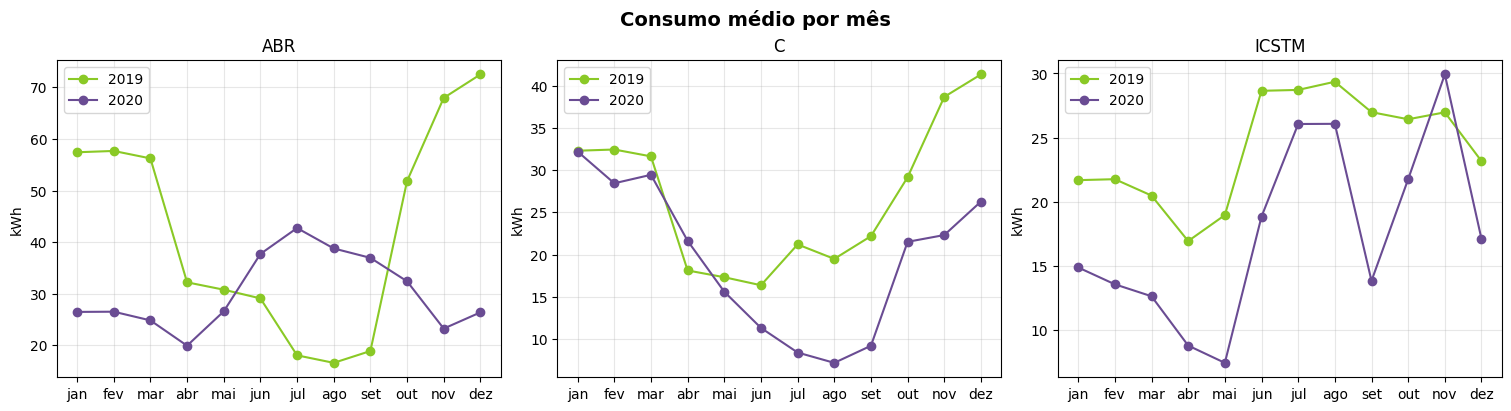

In [89]:
mensal = d.groupby(["edificio", "ano", d.index.month])["consumo"].mean()
meses = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, ed in zip(axes, EDIFICIOS):
    for a in anos:
        ax.plot(range(1, 13), mensal.loc[(ed, a)].values, marker="o", color=CORES[a], label=str(a))
    ax.set_title(f"{ed}: consumo médio por mês")
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(meses)
    ax.set_ylabel("kWh"); ax.legend(); ax.grid(alpha=0.3)
    ax.set_title(ed)
fig.suptitle("Consumo médio por mês", fontsize=14, fontweight="bold")
plt.show()

Nestes gráficos, observa-se que:
- No edifício ABR, em 2019, o consumo é mais alto no inverno e mais baixo no verão. Em 2020 o padrão quase se inverte, com o inverno mais baixo e o pico no mês de julho.
- No edifício C, quer em 2019 quer em 2020, o consumo é mais alto no inverno e mais baixo no verão, sendo o verão de 2020 o período com menos consumo.
- No edifício ICSTM, o consumo é mais irregular. Em 2019 é mais alto entre junho e novembro, enquanto em 2020 é muito baixo entre março e maio, subindo nos meses de verão e descendo em setembro (onde está a sequência de 64 horas sem consumo), para voltar depois a subir em outubro e novembro.

## Padrões diários, semanais e sazonais

### Relação do consumo com horas e dias anteriores

In [90]:
# Autocorrelação: confirma ciclos diários (24h) e semanais (168h)
rotulos = {
    1:   "hora anterior",
    24:  "mesma hora, dia anterior",
    168: "mesma hora, semana anterior",
}
ac = {(ed, a): {rot: round(d[(d.edificio == ed) & (d.ano == a)]["consumo"].autocorr(l), 3)
                for l, rot in rotulos.items()}
      for ed in EDIFICIOS for a in anos}
pd.DataFrame(ac).T

hora anterior  mesma hora, dia anterior  \
ABR   2019          0.974                     0.833   
      2020          0.919                     0.767   
C     2019          0.965                     0.874   
      2020          0.965                     0.873   
ICSTM 2019          0.662                     0.678   
      2020          0.498                     0.653   

            mesma hora, semana anterior  
ABR   2019                        0.858  
      2020                        0.753  
C     2019                        0.760  
      2020                        0.831  
ICSTM 2019                        0.679  
      2020                        0.600

Esta tabela mostra o quanto o consumo atual se relaciona com o consumo de horas e dias anteriores (autocorrelação). \
Pode-se verificar com base nos valores que a relação mais forte é com a hora anterior (0,92 a 0,97 no ABR e no C), seguida da mesma hora do dia anterior (0,65 a 0,87), o que confirma o ciclo diário.\
O edifício ICSTM será o mais difícil de prever, pois tem a relação mais fraca (0,50 a 0,66 com a hora anterior).

### Padrão diário

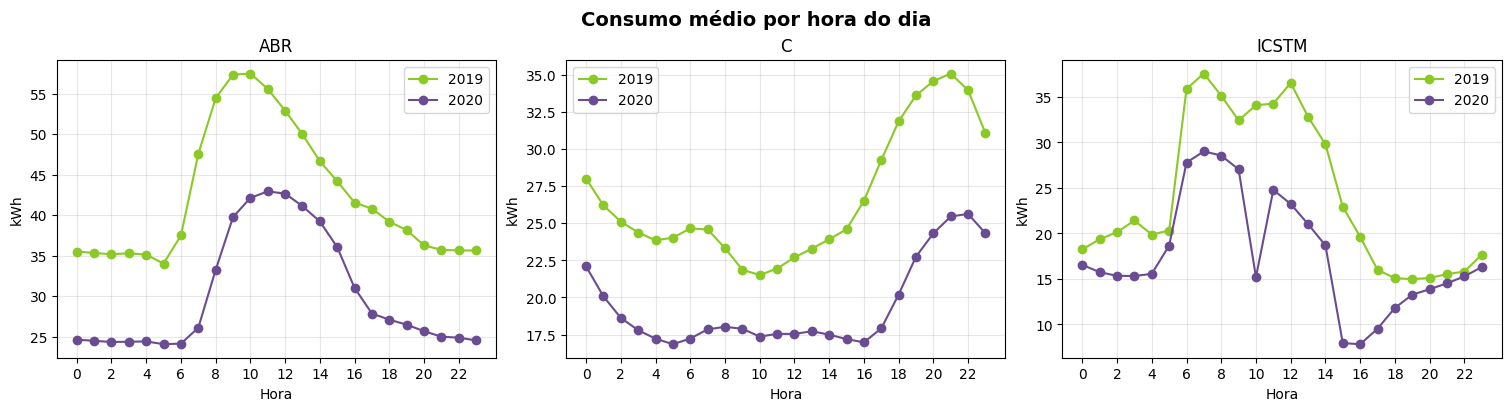

In [91]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, ed in zip(axes, EDIFICIOS):
    for a in anos:
        p = d[(d.edificio == ed) & (d.ano == a)].groupby("hora")["consumo"].mean()
        ax.plot(p.index, p.values, marker="o", color=CORES[a], label=str(a))
    ax.set_title(f"{ed}: consumo médio por hora do dia")
    ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Hora"); ax.set_ylabel("kWh")
    ax.legend(); ax.grid(alpha=0.3)
    ax.set_title(ed)
fig.suptitle("Consumo médio por hora do dia", fontsize=14, fontweight="bold")
plt.show()

Nos gráficos, pode-se verificar que:
- **No ABR o consumo é maior durante a manhã**, com o pico entre as 10h e as 11h;
- **No C é maior ao fim do dia**, com o pico entre as 21h e as 22h;
- **No ICSTM é maior entre as 6h e as 14h**, descendo bastante a partir das 15h.

O padrão é igual nos dois anos, mas com valores mais baixos em 2020.

### Padrão semanal

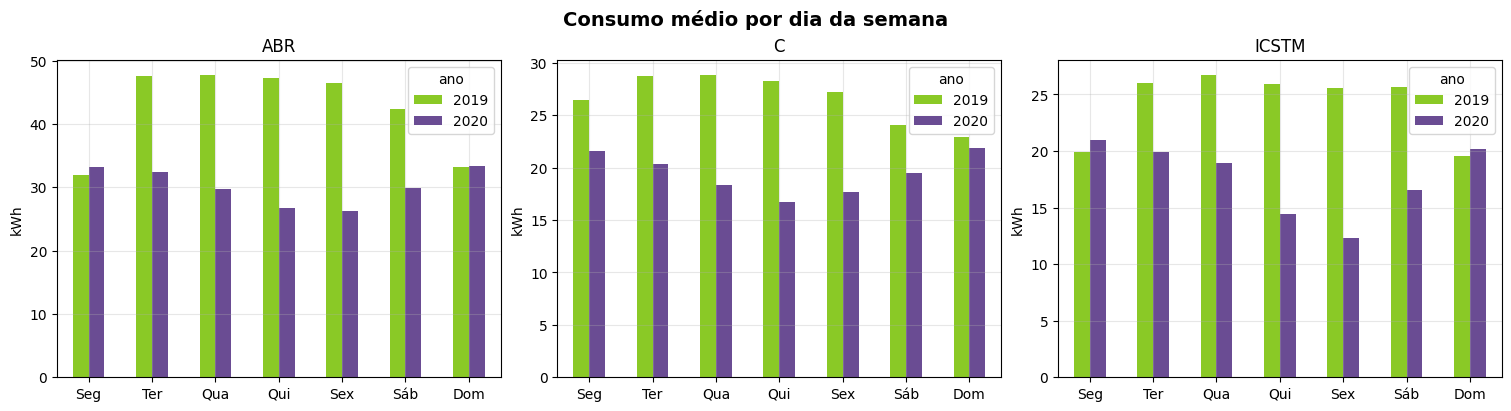

In [92]:
dias = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, ed in zip(axes, EDIFICIOS):
    p = d[d.edificio == ed].groupby(["dia_semana", "ano"])["consumo"].mean().unstack()
    p.index = dias
    p.plot(kind="bar", color=[CORES[a] for a in p.columns], ax=ax, rot=0)
    ax.set_title(f"{ed}: consumo médio por dia da semana")
    ax.set_xlabel(""); ax.set_ylabel("kWh"); ax.grid(alpha=0.3)
    ax.set_title(ed)
fig.suptitle("Consumo médio por dia da semana", fontsize=14, fontweight="bold")
plt.show()

Nos gráficos, pode-se verificar que, **em 2019, o consumo é maior entre terça e sexta-feira** e **menor ao domingo nos três edifícios**. \
No ABR e no ICSTM, a segunda-feira também tem um consumo baixo, semelhante ao do domingo sendo que, em 2020, este padrão desaparece, e a segunda-feira e o domingo passam a ser os dias com maior consumo nos três edifícios.

### Padrão sazonal

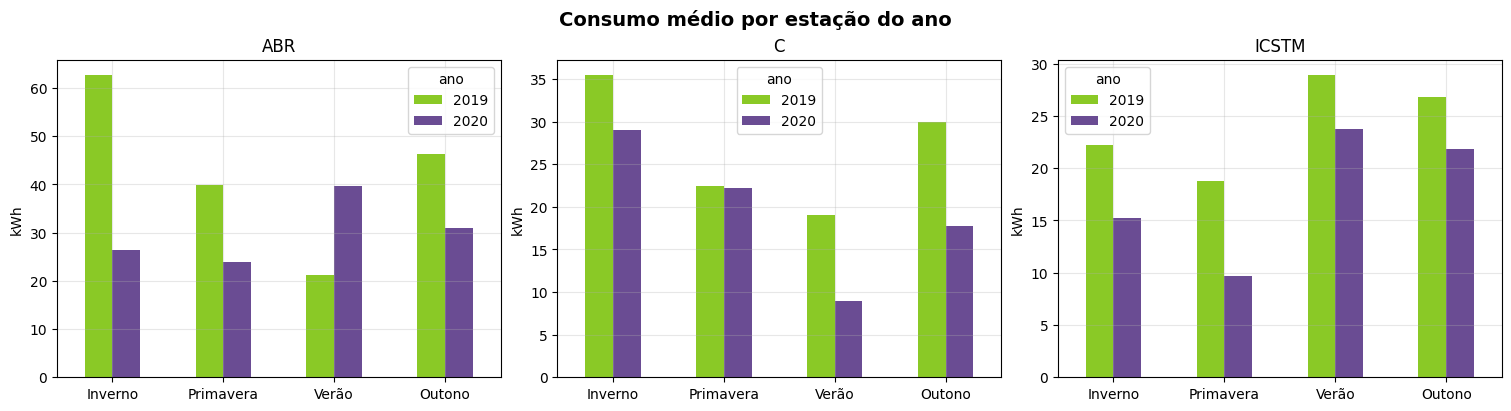

In [93]:
estacao_mes = {12: "Inverno", 1: "Inverno", 2: "Inverno",
               3: "Primavera", 4: "Primavera", 5: "Primavera",
               6: "Verão", 7: "Verão", 8: "Verão",
               9: "Outono", 10: "Outono", 11: "Outono"}
ordem = ["Inverno", "Primavera", "Verão", "Outono"]

d["estacao"] = d.index.month.map(estacao_mes)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, ed in zip(axes, EDIFICIOS):
    p = d[d.edificio == ed].groupby(["estacao", "ano"])["consumo"].mean().unstack().loc[ordem]
    p.plot(kind="bar", color=[CORES[a] for a in p.columns], ax=ax, rot=0)
    ax.set_title(f"{ed}: consumo médio por estação do ano")
    ax.set_xlabel(""); ax.set_ylabel("kWh"); ax.grid(alpha=0.3)
    ax.set_title(ed)
fig.suptitle("Consumo médio por estação do ano", fontsize=14, fontweight="bold")
plt.show()

Nos gráficos, pode-se verificar que 
- **No edifício C o consumo é maior no inverno do que no verão** nos dois anos;
- **No ABR, em 2019, o consumo é maior no inverno** e, **em 2020, o consumo é maior no verão**;
- **No ICSTM, o consumo é maior no verão e no outono** do que nas restantes estações em ambos os anos.

## Períodos de consumo elevado ou reduzido

In [94]:
diario = d.groupby(["edificio", "ano"])["consumo"].resample("D").sum(min_count=1).dropna()
for ed in EDIFICIOS:
    for a in anos:
        dd = diario.loc[(ed, a)]
        g = d[(d.edificio == ed) & (d.ano == a)]
        mh = g.groupby("hora")["consumo"].mean(); mm = g.groupby("mes")["consumo"].mean()
        print(f"===== {ed} {a} =====")
        print("Dias de maior consumo :", ", ".join(f"{i.date()} ({v:.0f})" for i, v in dd.nlargest(5).items()))
        print("Dias de menor consumo :", ", ".join(f"{i.date()} ({v:.0f})" for i, v in dd.nsmallest(5).items()))
        print(f"Hora de pico médio: {mh.idxmax()}h | hora de mínimo médio: {mh.idxmin()}h")
        print(f"Mês de maior consumo: {mm.idxmax()} | mês de menor consumo: {mm.idxmin()}\n")

===== ABR 2019 =====
Dias de maior consumo : 2019-12-20 (2530), 2019-12-19 (2526), 2019-12-21 (2355), 2019-11-07 (2254), 2019-12-18 (2186)
Dias de menor consumo : 2019-07-15 (335), 2019-07-08 (336), 2019-07-01 (342), 2019-07-22 (348), 2019-07-14 (349)
Hora de pico médio: 10h | hora de mínimo médio: 5h
Mês de maior consumo: 12 | mês de menor consumo: 8

===== ABR 2020 =====
Dias de maior consumo : 2020-07-27 (1373), 2020-10-11 (1265), 2020-07-26 (1250), 2020-10-12 (1243), 2020-07-25 (1222)
Dias de menor consumo : 2020-05-08 (305), 2020-04-30 (306), 2020-05-07 (308), 2020-04-22 (309), 2020-04-09 (312)
Hora de pico médio: 11h | hora de mínimo médio: 5h
Mês de maior consumo: 7 | mês de menor consumo: 4

===== C 2019 =====
Dias de maior consumo : 2019-12-04 (1384), 2019-12-03 (1331), 2019-11-20 (1290), 2019-01-15 (1290), 2019-12-17 (1289)
Dias de menor consumo : 2019-04-29 (296), 2019-04-28 (301), 2019-04-08 (304), 2019-04-07 (316), 2019-05-04 (318)
Hora de pico médio: 21h | hora de mínimo 

Com base nestes resultados, observa-se que:
- **No ABR, em 2019, os dias de maior consumo estão em dezembro e os de menor consumo em julho**, o que confirma o padrão sazonal anteriormente identificado. **Em 2020 isto inverte-se**, com os dias de maior consumo no final de julho e os de menor consumo entre abril e maio.
- **No C, os dias de maior consumo estão no inverno nos dois anos** (dezembro de 2019 e janeiro de 2020) e os de **menor consumo na primavera de 2019 e no fim do verão de 2020**.
- No ICSTM, em 2020, os dias de menor consumo são 1 a 3 de setembro, que correspondem à **sequência de 64 horas sem consumo identificada anteriormente**.
- **A hora de maior consumo é diferente em cada edifício** (10–11h no ABR, 21–22h no C e 7h no ICSTM), e a de **menor consumo é por volta das 5h no ABR, mas varia no C e no ICSTM**.

---
# 4.2. Preparação dos dados

## Verificação e ordenação temporal dos registos

In [95]:
dp = d.copy().sort_index(kind="stable")      # ordenação temporal (a ordem dentro de cada hora não importa)
linhas = []
for ed in EDIFICIOS:
    s = dp[dp.edificio == ed]["consumo"]
    linhas.append({"edifício": ed, "registos": len(s),
                   "ordem crescente": s.index.is_monotonic_increasing,
                   "sem datas repetidas": s.index.is_unique,
                   "início": s.index.min(), "fim": s.index.max()})
pd.DataFrame(linhas).set_index("edifício")

,registos,ordem crescente,sem datas repetidas,início,fim
edifício,,,,,
ABR,17520,True,True,2019-01-01,2020-12-31 23:00:00
C,17520,True,True,2019-01-01,2020-12-31 23:00:00
ICSTM,17520,True,True,2019-01-01,2020-12-31 23:00:00


Na tabela, pode-se verificar que cada edifício tem 17520 registos, sem datas repetidas e todos com a mesma data de início e fim.

## Tratamento de valores em falta ou inválidos

Neste passo, identificam-se as **sequências de horas com consumo igual a zero em cada edifício**. \
As sequências até 3 horas seguidas são substituídas por **interpolação linear entre o consumo anterior e o seguinte**, e as mais longas são mantidas e assinaladas. \
O consumo original fica guardado na coluna `consumo_original`.

In [96]:
LIMITE_H = 3          # blocos de zeros com até 3 h consecutivas são interpolados

dp["consumo_original"] = dp["consumo"]
partes = []
for ed in EDIFICIOS:
    g = dp[dp.edificio == ed].copy()
    z = g["consumo_original"] <= 0
    bloco = (z != z.shift()).cumsum()                    # identifica cada sequência de zeros
    tamanho = z.groupby(bloco).transform("size")        # comprimento da sequência a que cada zero pertence
    g["zero_curto"] = z & (tamanho <= LIMITE_H)
    g["zero_longo"] = z & (tamanho > LIMITE_H)
    g["consumo"] = g["consumo_original"].mask(g["zero_curto"]).interpolate(method="time")
    partes.append(g)
dp = pd.concat(partes).sort_index(kind="stable")

resumo = dp.groupby(["edificio", "ano"]).agg(zeros_total=("consumo_original", lambda s: int((s <= 0).sum())),
                                              interpolados=("zero_curto", "sum"),
                                              mantidos=("zero_longo", "sum"))
resumo

zeros_total  interpolados  mantidos
edificio ano                                      
ABR      2019            0             0         0
         2020            0             0         0
C        2019            0             0         0
         2020            0             0         0
ICSTM    2019           17             9         8
         2020          652           239       413

Tendo em conta que apenas o ICSTM tinha zeros, foi o único edifício que sofreu um tratamento nesse sentido. \
Foram interpoladas 9 horas em 2019 e 239 horas em 2020 e mantidas 8 horas em 2019 e 413 horas em 2020, por pertencerem a blocos mais longos que podem corresponder a paragens reais do edifício.

## Identificação de valores atípicos

In [97]:
LIMIAR_DP = 3
chave = [dp["edificio"], dp["ano"], dp["hora"], dp["dia_semana"]]
media = dp.groupby(chave)["consumo"].transform("mean")
desvio_padrao = dp.groupby(chave)["consumo"].transform("std")
dp["desvio_z"] = (dp["consumo"] - media) / desvio_padrao.replace(0, np.nan)
dp["atipico"] = dp["desvio_z"].abs() > LIMIAR_DP

t = dp.groupby(["edificio", "ano"])["atipico"].agg(["sum", "mean"])
t.columns = ["horas atípicas", "% horas atípicas"]; t["% horas atípicas"] = (100 * t["% horas atípicas"]).round(1); t

horas atípicas  % horas atípicas
edificio ano                                   
ABR      2019             112               1.3
         2020              17               0.2
C        2019              16               0.2
         2020               9               0.1
ICSTM    2019             125               1.4
         2020             173               2.0

Com base na tabela, pode-se verificar que:
- **O ICSTM é o edifício com mais horas atípicas**, sobretudo em 2020;
- **O ABR tem valores semelhantes ao ICSTM em 2019**, mas em 2020 desce para 17 horas; 
- **O C é o edifício mais regular**, com 16 horas em 2019 e 9 horas em 2020. 

Em todos os casos, os valores atípicos foram assinalados, mas mantidos, por poderem corresponder a consumo real.

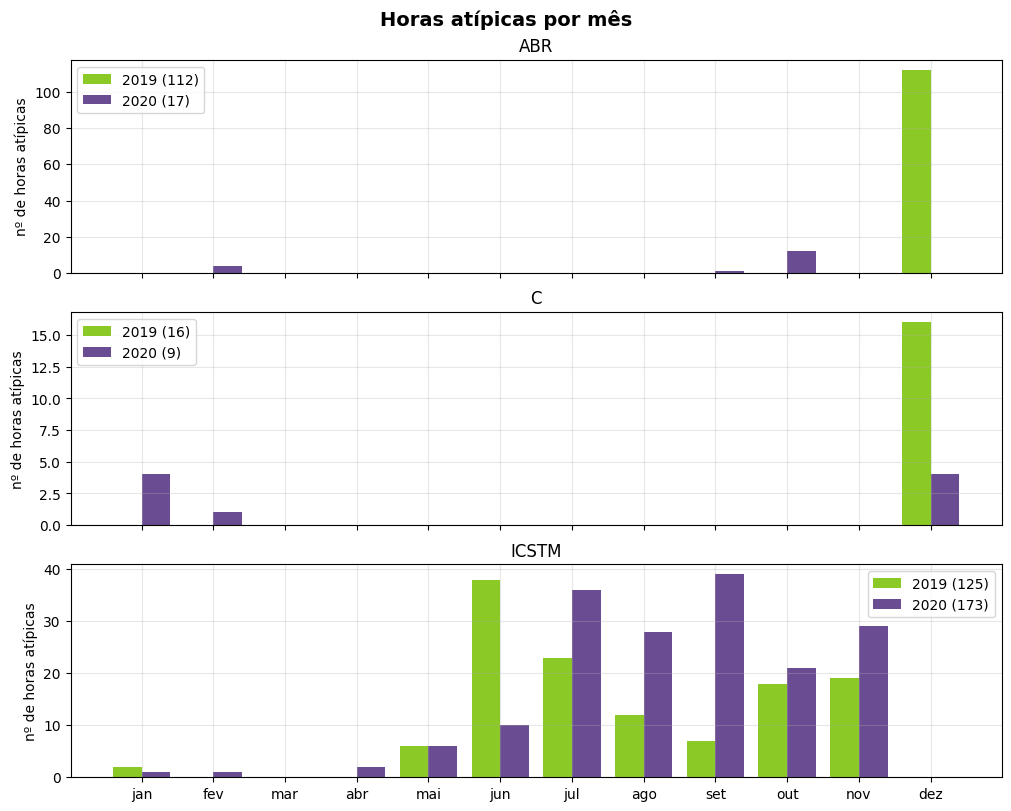

In [98]:
por_mes = dp.groupby(["edificio", "ano", dp.index.month])["atipico"].sum()
meses = np.arange(1, 13)
largura = 0.4

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True, constrained_layout=True)
for ax, ed in zip(axes, EDIFICIOS):
    for i, a in enumerate([2019, 2020]):
        v = por_mes[ed][a].reindex(meses, fill_value=0)
        ax.bar(meses + (i - 0.5) * largura, v, width=largura, color=[CORES[a] for _ in range(len(v))], label=f"{a} ({int(v.sum())})")
    ax.set_title(f"{ed}")
    ax.set_ylabel("nº de horas atípicas");
    ax.legend(); ax.grid(axis="y", alpha=0.3)
axes[-1].set_xticks(meses)
axes[-1].set_xticklabels(["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"])
fig.suptitle("Horas atípicas por mês", fontsize=14, fontweight="bold")
plt.show()

Aqui, pode-se verificar que **no ABR e no C os valores atípicos estão concentrados em dezembro de 2019**, enquanto **no ICSTM surgem sobretudo entre junho e novembro dos dois anos**, os meses em que o consumo deste edifício tem picos mais altos.

## Verificação da periodicidade dos registos

In [99]:
linhas = []
for ed in EDIFICIOS:
    g = dp[dp.edificio == ed]
    s = g["consumo"]
    dif = g.groupby("ano")["hora_ano"].diff().dropna()          # horas entre registos consecutivos (dentro de cada ano)
    linhas.append({"edifício": ed,
                   "intervalos distintos": dif.nunique(),
                   "intervalo (h)": int(dif.iloc[0]),
                   "saltos ≠ 1h": int((dif != 1).sum()),
                   "2019 → 2020 contínuo": s[s.index.year == 2019].index.max() + pd.Timedelta("1h") == s[s.index.year == 2020].index.min(),
                   "dias em 2019": s[s.index.year == 2019].index.normalize().nunique(),
                   "dias em 2020": s[s.index.year == 2020].index.normalize().nunique()})
pd.DataFrame(linhas).set_index("edifício")

,intervalos distintos,intervalo (h),saltos ≠ 1h,2019 → 2020 contínuo,dias em 2019,dias em 2020
edifício,,,,,,
ABR,1,1,0,True,365,365
C,1,1,0,True,365,365
ICSTM,1,1,0,True,365,365


Com base na tabela, verifica-se que **a periodicidade é de 1 hora em todos os edifícios**, sem falhas. \
Na nossa análise, **2020 tem 365 dias em vez de 366** por convenção para ficar comparável com 2019.

## Criação de variáveis temporais

### Variáveis criadas

In [100]:
# Posição da hora num relógio de 24 h (x = cosseno, y = seno)
dp["hora_relogio_y"] = np.sin(2 * np.pi * dp["hora"] / 24);       dp["hora_relogio_x"] = np.cos(2 * np.pi * dp["hora"] / 24)

# Consumos anteriores (dentro de cada edifício; as linhas são consecutivas, com 1 h entre registos, e 29 fev 2020 não existe)
for k, nome in {1: "consumo_hora_anterior", 24: "consumo_dia_anterior"}.items():
    dp[nome] = dp.groupby("edificio")["consumo"].shift(k)

FEATURES_BASE = ["hora_relogio_y", "hora_relogio_x", "consumo_hora_anterior", "consumo_dia_anterior"]

print("Linhas sem consumo anterior (início da série de cada edifício):", dp["consumo_dia_anterior"].isna().sum() // len(EDIFICIOS), "por edifício")
dp[dp.edificio == "ABR"][["consumo"] + FEATURES_BASE].iloc[[0, 1, 24, 25, 26]].round(3)

Linhas sem consumo anterior (início da série de cada edifício): 24 por edifício


,consumo,hora_relogio_y,hora_relogio_x,consumo_hora_anterior,consumo_dia_anterior
2019-01-01 00:00:00,44.630,0.000,1.000,NaN,NaN
2019-01-01 01:00:00,45.302,0.259,0.966,44.630,NaN
2019-01-02 00:00:00,44.569,0.000,1.000,44.459,44.630
2019-01-02 01:00:00,44.960,0.259,0.966,44.569,45.302
2019-01-02 02:00:00,43.812,0.500,0.866,44.960,43.848


Nesta fase, fez-se as seguintes modificações:
- Criou-se as variáveis `hora_relogio_x` e `hora_relogio_y`, que foram calculadas a partir de senos e cossenos para se saber qual a posição de cada hora no relógio. Assim, quando ocorrer o treino, não se assume que as 23h está longe da 00h, por exemplo.
- Criou-se as variáveis `consumo_hora_anterior`, que corresponde ao consumo na hora anterior, e `consumo_dia_anterior`, que corresponde ao consumo na mesma hora, mas no dia anterior. Estas variáveis foram calculadas para cada edifício com o consumo já tratado.

## Guardar em CSV

In [101]:
colunas = ["edificio", "consumo"] + FEATURES_BASE + ["consumo_original", "zero_longo", "atipico"]
dados_prontos = dp[colunas]

pasta = RAIZ / "dataset" / "final"
pasta.mkdir(exist_ok=True)
dados_prontos.to_csv(pasta / "electrical_demand.csv", index_label="data_hora")
print(dados_prontos.groupby("edificio").size().to_dict(), "| total:", len(dados_prontos))

{'ABR': 17520, 'C': 17520, 'ICSTM': 17520} | total: 52560
